# Next-month link prediction — baselines, feature ablations, GNN

## 1. Load trips, build monthly snapshots

In [1]:
import os, re, numpy as np, pandas as pd, matplotlib.pyplot as plt

DATA = os.environ.get("CHENNAI_DATA", "../../GNN-TRANSPORTATION/aadarsh-bikeshare/chennai")
OUT  = "outputs/results"; os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.autolayout": True})
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a9298"
key = lambda s: re.sub(r"[^a-z0-9]+", " ", str(s).lower().replace("\u2013", "-")).strip()

df = pd.read_excel(f"{DATA}/bikesharing2.xlsx", sheet_name="tripdata")
df = df.drop_duplicates().dropna(subset=["pickup_station", "drop_station"])
df = df[df.vehicle_type != "SmartBike"]                    # 4 stray rows, not a bike class
df["o"], df["d"] = df.pickup_station.map(key), df.drop_station.map(key)
df = df[~(df.o.str.contains("amma arangam|test") | df.d.str.contains("amma arangam|test"))]
df["t"] = pd.to_datetime(df.ride_start_time)
df["month"] = df.t.dt.to_period("M")
df["weekend"] = df.t.dt.dayofweek >= 5

nodes = sorted(set(df.o) | set(df.d)); ix = {n: i for i, n in enumerate(nodes)}; N = len(nodes)
months = sorted(df.month.unique()); T = len(months)

S  = np.zeros((T, N, N))      # one-way trips per month (self-loops excluded)
SW = np.zeros((T, N, N))      # of which on weekends
for t, m in enumerate(months):
    sl = df[(df.month == m) & (df.o != df.d)]
    for (o, d), w in sl.groupby(["o", "d"]).size().items():             S[t, ix[o], ix[d]] = w
    for (o, d), w in sl[sl.weekend].groupby(["o", "d"]).size().items(): SW[t, ix[o], ix[d]] = w

st = pd.read_excel(f"{DATA}/bikesharing2.xlsx", sheet_name="109 live stations")
st.columns = [x.strip() for x in st.columns]
st = st.dropna(subset=["Station Name"]).copy(); st["o"] = st["Station Name"].map(key)
st.loc[st.Latitude > 90, "Latitude"] /= 1e6
st = st.drop_duplicates("o").set_index("o")
lat, lon = st.Latitude.reindex(nodes).values, st.Longitude.reindex(nodes).values
HAS_XY = np.isfinite(lat) & np.isfinite(lon)

R = 6371.0; p = np.radians(np.c_[np.nan_to_num(lat), np.nan_to_num(lon)])
hv = np.sin((p[:, None, 0] - p[None, :, 0]) / 2) ** 2 + \
     np.cos(p[:, None, 0]) * np.cos(p[None, :, 0]) * np.sin((p[:, None, 1] - p[None, :, 1]) / 2) ** 2
DIST = 2 * R * np.arcsin(np.sqrt(hv))
XYOK = HAS_XY[:, None] & HAS_XY[None, :]
DIST = np.where(XYOK, DIST, np.median(DIST[XYOK]))         # imputed, flagged by a feature

OFFDIAG = ~np.eye(N, dtype=bool)
print(f"{N} stations | {T} months | {OFFDIAG.sum():,} directed candidate pairs")
print(f"active pairs per month: mean {np.mean([(S[t] > 0).sum() for t in range(T)]):.0f} "
      f"({np.mean([(S[t] > 0).sum() for t in range(T)]) / OFFDIAG.sum():.1%})")

114 stations | 20 months | 12,882 directed candidate pairs
active pairs per month: mean 1075 (8.3%)


## 2. Station age proxy — first recorded ride

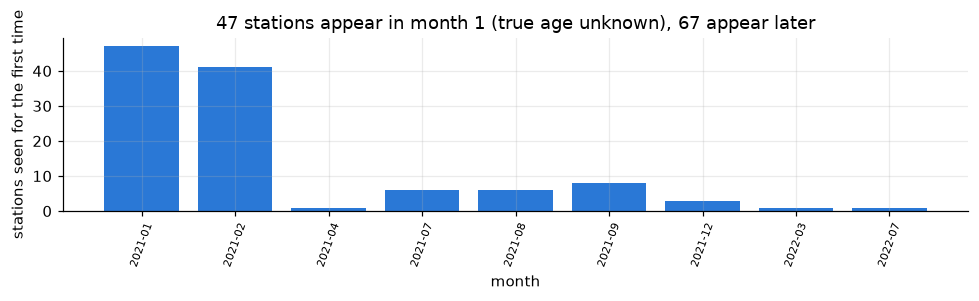

In [2]:
# No opening dates exist, so the first month a station appears is the only proxy available.
# It is a LOWER bound: a station open before Jan 2021 looks as if it started then.
first_seen = np.full(N, -1)
for t in range(T):
    seen = (S[t] > 0).any(1) | (S[t] > 0).any(0)
    first_seen[(first_seen < 0) & seen] = t

cnt = pd.Series(first_seen).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.bar([str(months[i]) for i in cnt.index], cnt.values, color=BLUE)
ax.set(ylabel="stations seen for the first time", xlabel="month",
       title=f"{(first_seen == 0).sum()} stations appear in month 1 (true age unknown), "
             f"{(first_seen > 0).sum()} appear later")
ax.tick_params(axis="x", rotation=70, labelsize=7)
plt.show()

## 3. Pair feature blocks

In [3]:
SEASON = {1:"winter",2:"winter",3:"summer",4:"summer",5:"summer",
          6:"sw_monsoon",7:"sw_monsoon",8:"sw_monsoon",9:"sw_monsoon",
          10:"ne_monsoon",11:"ne_monsoon",12:"ne_monsoon"}      # IMD calendar

def build(t):
    """Pair features for target month t, from months 0..t-1 only. block -> (names, matrix)."""
    prev, hist = S[t-1], S[:t].sum(0)
    act  = (S[:t] > 0).sum(0)
    ever = (S[:t] > 0)
    since_last = np.where(ever.any(0), t - 1 - np.argmax(ever[::-1], axis=0), t)

    H = {"log_trips_prev": np.log1p(prev),
         "log_trips_hist": np.log1p(hist),
         "frac_active":    act / t,
         "months_since":   since_last / t}
    St = {"log_out_origin": np.log1p(np.broadcast_to(prev.sum(1, keepdims=True), prev.shape)),
          "log_in_dest":    np.log1p(np.broadcast_to(prev.sum(0, keepdims=True), prev.shape)),
          "reverse_active": (prev.T > 0).astype(float)}
    D = {"log_distance": np.log1p(DIST),
         "xy_missing":   (~XYOK).astype(float)}
    age = np.clip(t - first_seen, 0, None).astype(float)
    A = {"age_origin":    np.broadcast_to(age[:, None], prev.shape) / T,
         "age_dest":      np.broadcast_to(age[None, :], prev.shape) / T,
         "age_min":       np.minimum.outer(age, age) / T,
         "origin_is_new": np.broadcast_to((age[:, None] <= 1).astype(float), prev.shape),
         "dest_is_new":   np.broadcast_to((age[None, :] <= 1).astype(float), prev.shape)}
    wk = np.divide(SW[:t].sum(0), hist, out=np.zeros_like(hist), where=hist > 0)
    same = [j for j in range(t) if SEASON[months[j].month] == SEASON[months[t].month]]
    W = {"pair_weekend_share": wk,
         "season_trips":       np.log1p(S[same].sum(0)) if same else np.zeros_like(prev),
         "is_summer":          np.full(prev.shape, float(SEASON[months[t].month] == "summer")),
         "is_sw_monsoon":      np.full(prev.shape, float(SEASON[months[t].month] == "sw_monsoon")),
         "is_ne_monsoon":      np.full(prev.shape, float(SEASON[months[t].month] == "ne_monsoon"))}

    return {g: (list(b), np.stack([v[OFFDIAG] for v in b.values()], 1))
            for g, b in [("H", H), ("S", St), ("D", D), ("A", A), ("W", W)]}

def labels(t):    return (S[t] > 0)[OFFDIAG].astype(float)
def seen_pair(t):
    s = (first_seen >= 0) & (first_seen < t); return (s[:, None] & s[None, :])[OFFDIAG]
def groups(t):
    prev = (S[t-1] > 0)[OFFDIAG]; ever = (S[:t] > 0).any(0)[OFFDIAG]
    g = np.full(OFFDIAG.sum(), "novel", dtype=object)
    g[ever & ~prev] = "returning"; g[prev] = "recurring"; return g

for g, (names, M) in build(6).items(): print(f"{g}  {M.shape[1]}  {names}")

H  4  ['log_trips_prev', 'log_trips_hist', 'frac_active', 'months_since']
S  3  ['log_out_origin', 'log_in_dest', 'reverse_active']
D  2  ['log_distance', 'xy_missing']
A  5  ['age_origin', 'age_dest', 'age_min', 'origin_is_new', 'dest_is_new']
W  5  ['pair_weekend_share', 'season_trips', 'is_summer', 'is_sw_monsoon', 'is_ne_monsoon']


## 4. Metrics and the logistic model

In [4]:
from sklearn.metrics import average_precision_score, roc_auc_score

# Ties matter here: persistence gives the same score to every pair with the same
# trip count last month, and 99.8% of its scores are duplicates. A hand-rolled
# ranking that breaks ties by array order flatters such a model. sklearn applies
# the standard tie corrections, so both metrics come from there.
def ap(y, s):   return average_precision_score(y, s)
def auc(y, s):  return roc_auc_score(y, s)
def p_at_k(y, s, k=None):
    k = int(y.sum()) if k is None else k      # k = positives in the month unless given
    return y[np.argsort(-s)[:k]].mean()
def recall_at_k(y, s, k=500): return y[np.argsort(-s)[:k]].sum() / y.sum()

def logistic(Xtr, ytr, Xte, epochs=250, lr=.5):
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-9
    A_ = np.c_[(Xtr - mu) / sd, np.ones(len(Xtr))]
    B_ = np.c_[(Xte - mu) / sd, np.ones(len(Xte))]
    w = np.zeros(A_.shape[1])
    for _ in range(epochs):
        w -= lr * A_.T @ (1 / (1 + np.exp(-A_ @ w)) - ytr) / len(ytr)
    return 1 / (1 + np.exp(-B_ @ w)), w

print("metrics: sklearn average_precision_score / roc_auc_score (tie-corrected)")

metrics: sklearn average_precision_score / roc_auc_score (tie-corrected)


## 5. Rolling folds — baselines and feature configs

In [5]:
WARMUP, FIRST = 4, 6
folds = list(range(FIRST, T))
cache = {t: build(t) for t in range(WARMUP, T)}        # built once, reused by every config

def design(t, blocks): return np.concatenate([cache[t][g][1] for g in blocks], axis=1)

CONFIGS = {
    "H  history only":        ["H"],
    "HS  +station activity":  ["H", "S"],
    "HSD  +distance":         ["H", "S", "D"],
    "HSDA  +age":             ["H", "S", "D", "A"],
    "HSDW  +calendar":        ["H", "S", "D", "W"],
    "HSDAW  full":            ["H", "S", "D", "A", "W"],
    "SDAW  full -history":    ["S", "D", "A", "W"],
}
MAIN   = "HSD  +distance"       # expanding window, months 4..t-1
MATCH  = "HSD-3mo matched"      # same features, but only the last 3 months, like the GNN
GNN_WINDOW = 3

rows, keep = [], {}
for t in folds:
    yte = labels(t)
    scores = {"B0a persistence": S[t-1][OFFDIAG],          # last month's trips
              "B0b any past":    S[:t].sum(0)[OFFDIAG]}    # EdgeBank: every past month
    for name, blocks in CONFIGS.items():
        Xtr = np.vstack([design(j, blocks) for j in range(WARMUP, t)])
        ytr = np.concatenate([labels(j) for j in range(WARMUP, t)])
        s, w = logistic(Xtr, ytr, design(t, blocks))
        scores[name] = s
        if name == MAIN: last_w, last_names = w, sum([cache[t][g][0] for g in blocks], [])

    # matched-window control: identical features to MAIN, identical months to the GNN
    mw = list(range(max(WARMUP, t - GNN_WINDOW), t))
    Xtr = np.vstack([design(j, ["H", "S", "D"]) for j in mw])
    ytr = np.concatenate([labels(j) for j in mw])
    scores[MATCH] = logistic(Xtr, ytr, design(t, ["H", "S", "D"]))[0]

    keep[t] = (yte, scores)
    for name, s in scores.items():
        rows.append({"month": str(months[t]), "model": name, "positives": int(yte.sum()),
                     "AP": ap(yte, s), "AUC": auc(yte, s),
                     "P@k": p_at_k(yte, s), "P@500": p_at_k(yte, s, 500),
                     "R@500": recall_at_k(yte, s)})

res = pd.DataFrame(rows)
print(f"{len(folds)} folds | mean positives {res.positives.mean():.0f} "
      f"({res.positives.mean()/OFFDIAG.sum():.1%} of candidates)")
print("P@k uses k = the month's positive count; P@500 is a fixed operational budget.")
print()
res.groupby("model").agg(AP=("AP","mean"), AP_sd=("AP","std"), AUC=("AUC","mean"),
                         Pk=("P@k","mean"), P500=("P@500","mean"),
                         R500=("R@500","mean")).round(3).sort_values("AP", ascending=False)

14 folds | mean positives 1239 (9.6% of candidates)
P@k uses k = the month's positive count; P@500 is a fixed operational budget.



,AP,AP_sd,AUC,Pk,P500,R500
model,,,,,,
HSD-3mo matched,0.574,0.046,0.874,0.537,0.758,0.312
HSD +distance,0.572,0.045,0.875,0.537,0.756,0.311
HSDA +age,0.570,0.044,0.871,0.537,0.757,0.312
HSDAW full,0.570,0.046,0.872,0.535,0.755,0.311
HSDW +calendar,0.570,0.047,0.875,0.535,0.754,0.310
HS +station activity,0.558,0.048,0.858,0.525,0.762,0.313
H history only,0.533,0.046,0.826,0.520,0.759,0.312
SDAW full -history,0.533,0.044,0.859,0.509,0.714,0.294
B0b any past,0.512,0.042,0.825,0.513,0.736,0.303


## 6. GNN — two layers of mean aggregation over the monthly graph

In [6]:
import torch, torch.nn as nn

def node_features(t):
    """Per-station features for month t, from months 0..t-1 only."""
    prev, hist = S[t-1], S[:t].sum(0)
    rec = S[max(0, t-3):t].sum(0)
    age = np.clip(t - first_seen, 0, None) / T
    f = np.stack([
        np.log1p(prev.sum(1)), np.log1p(prev.sum(0)),          # trips out / in last month
        np.log1p(rec.sum(1)),  np.log1p(rec.sum(0)),           # trips out / in last 3 months
        (prev > 0).sum(1) / N, (prev > 0).sum(0) / N,          # out- / in-degree last month
        (hist > 0).sum(1) / N,                                  # partners ever
        age,
        np.nan_to_num(lat, nan=np.nanmean(lat)) - np.nanmean(lat),
        np.nan_to_num(lon, nan=np.nanmean(lon)) - np.nanmean(lon),
        HAS_XY.astype(float),
    ], 1)
    return (f - f.mean(0)) / (f.std(0) + 1e-9)

def adj_norm(t, window=3):
    """Row-normalised out- and in-adjacency from the last `window` months."""
    A = (S[max(0, t-window):t].sum(0) > 0).astype(np.float32)
    out = A / np.maximum(A.sum(1, keepdims=True), 1)
    inn = A.T / np.maximum(A.T.sum(1, keepdims=True), 1)
    return torch.tensor(out), torch.tensor(inn)

class SAGE(nn.Module):
    """Two layers of mean aggregation over out- and in-neighbours, kept deliberately small."""
    def __init__(self, f_in, h=32):
        super().__init__()
        self.l1 = nn.ModuleList([nn.Linear(f_in, h) for _ in range(3)])   # self, out-nbrs, in-nbrs
        self.l2 = nn.ModuleList([nn.Linear(h, h) for _ in range(3)])
        self.do = nn.Dropout(0.3)
    def forward(self, x, Aout, Ain):
        h = torch.relu(self.l1[0](x) + self.l1[1](Aout @ x) + self.l1[2](Ain @ x))
        h = self.do(h)
        return self.l2[0](h) + self.l2[1](Aout @ h) + self.l2[2](Ain @ h)

class Decoder(nn.Module):
    """Scores a directed pair from the two embeddings (+ optional pair features)."""
    def __init__(self, h=32, f_pair=0):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(3 * h + f_pair, 64), nn.ReLU(),
                                 nn.Dropout(0.3), nn.Linear(64, 1))
    def forward(self, z, I, J, pf=None):
        parts = [z[I], z[J], z[I] * z[J]]
        if pf is not None: parts.append(pf)
        return self.net(torch.cat(parts, 1)).squeeze(-1)

II, JJ = np.where(OFFDIAG)
I_t, J_t = torch.tensor(II), torch.tensor(JJ)

# cache the per-month tensors once; every fold and seed reuses them
XC, AC, PC, YC = {}, {}, {}, {}
for t in range(WARMUP, T):
    XC[t] = torch.tensor(node_features(t), dtype=torch.float32)
    AC[t] = adj_norm(t)
    pf = torch.tensor(design(t, ["H", "S", "D"]), dtype=torch.float32)
    PC[t] = (pf - pf.mean(0)) / (pf.std(0) + 1e-9)
    YC[t] = torch.tensor(labels(t), dtype=torch.float32)
print("node features:", XC[6].shape, "| pairs:", len(II), "| cached months:", len(XC))

node features: torch.Size([114, 11]) | pairs: 12882 | cached months: 16


In [7]:
def run_gnn(t, use_pair_feats=True, seed=0, epochs=150, train_window=3, lr=0.01):
    torch.manual_seed(seed)
    f_pair = PC[t].shape[1] if use_pair_feats else 0
    enc, dec = SAGE(XC[t].shape[1]), Decoder(f_pair=f_pair)
    opt = torch.optim.Adam(list(enc.parameters()) + list(dec.parameters()), lr=lr, weight_decay=1e-4)
    train_months = list(range(max(WARMUP, t - train_window), t))
    pw = torch.tensor(10.0)

    enc.train(); dec.train()
    for _ in range(epochs):
        for j in train_months:
            Ao, Ai = AC[j]
            opt.zero_grad()
            loss = nn.functional.binary_cross_entropy_with_logits(
                dec(enc(XC[j], Ao, Ai), I_t, J_t, PC[j] if use_pair_feats else None),
                YC[j], pos_weight=pw)
            loss.backward(); opt.step()

    enc.eval(); dec.eval()
    with torch.no_grad():
        Ao, Ai = AC[t]
        return torch.sigmoid(dec(enc(XC[t], Ao, Ai), I_t, J_t,
                                 PC[t] if use_pair_feats else None)).numpy()

SEEDS = [0, 1]          # ~15 s per run, so this cell takes about 15 minutes
gnn_rows = []
for t in folds:
    yte = labels(t)
    for tag, use_pf in [("G1 GNN + pair features", True), ("G2 GNN structure only", False)]:
        s = np.mean([run_gnn(t, use_pair_feats=use_pf, seed=sd) for sd in SEEDS], axis=0)
        keep[t][1][tag] = s
        gnn_rows.append({"month": str(months[t]), "model": tag, "positives": int(yte.sum()),
                         "AP": ap(yte, s), "AUC": auc(yte, s),
                         "P@k": p_at_k(yte, s), "P@500": p_at_k(yte, s, 500),
                         "R@500": recall_at_k(yte, s)})
    print(f"{months[t]} done", end="  ")

res = pd.concat([res, pd.DataFrame(gnn_rows)], ignore_index=True)
res.groupby("model").agg(AP=("AP","mean"), AP_sd=("AP","std"), AUC=("AUC","mean"),
                         Pk=("P@k","mean")).round(3).sort_values("AP", ascending=False)

2021-07 done  2021-08 done  2021-09 done  2021-10 done  2021-11 done  2021-12 done  2022-01 done  2022-02 done  2022-03 done  2022-04 done  2022-05 done  2022-06 done  2022-07 done  2022-08 done  

,AP,AP_sd,AUC,Pk
model,,,,
HSD-3mo matched,0.574,0.046,0.874,0.537
G1 GNN + pair features,0.573,0.049,0.876,0.541
HSD +distance,0.572,0.045,0.875,0.537
HSDA +age,0.570,0.044,0.871,0.537
HSDAW full,0.570,0.046,0.872,0.535
HSDW +calendar,0.570,0.047,0.875,0.535
HS +station activity,0.558,0.048,0.858,0.525
H history only,0.533,0.046,0.826,0.520
SDAW full -history,0.533,0.044,0.859,0.509


## 7. All models side by side

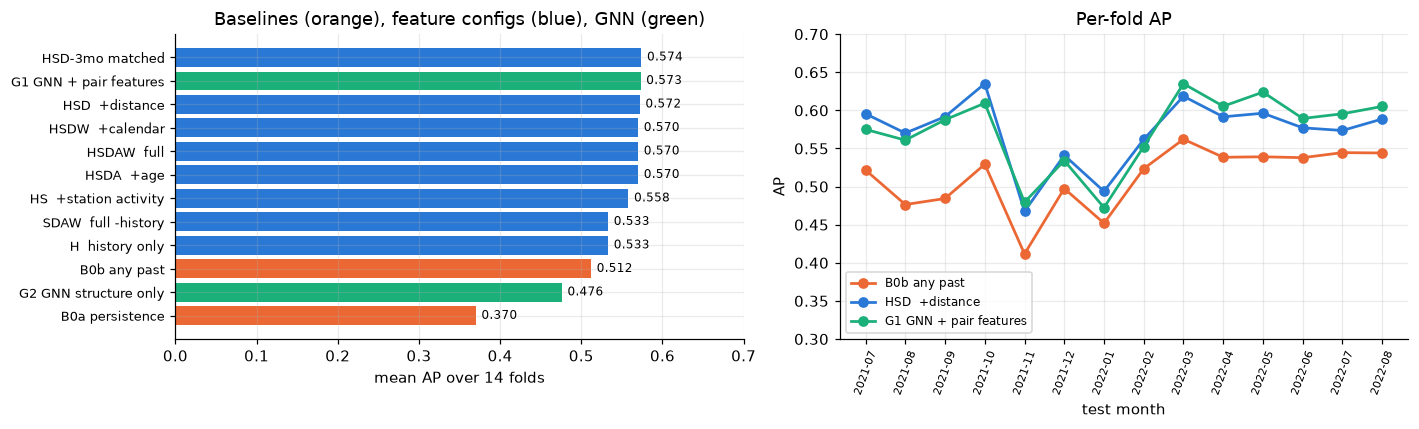

,AP,AP_sd,AUC,Pk,P500,R500
model,,,,,,
HSD-3mo matched,0.574,0.046,0.874,0.537,0.758,0.312
G1 GNN + pair features,0.573,0.049,0.876,0.541,0.760,0.313
HSD +distance,0.572,0.045,0.875,0.537,0.756,0.311
HSDA +age,0.570,0.044,0.871,0.537,0.757,0.312
HSDAW full,0.570,0.046,0.872,0.535,0.755,0.311
HSDW +calendar,0.570,0.047,0.875,0.535,0.754,0.310
HS +station activity,0.558,0.048,0.858,0.525,0.762,0.313
H history only,0.533,0.046,0.826,0.520,0.759,0.312
SDAW full -history,0.533,0.044,0.859,0.509,0.714,0.294


In [8]:
summary = res.groupby("model").agg(AP=("AP","mean"), AP_sd=("AP","std"), AUC=("AUC","mean"),
                                   Pk=("P@k","mean"), P500=("P@500","mean"),
                                   R500=("R@500","mean")).round(3)
order = summary.sort_values("AP").index
colour = {"B0": ORANGE, "G1": GREEN, "G2": GREEN}
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].barh(range(len(order)), summary.loc[order, "AP"],
           color=[colour.get(m[:2], BLUE) for m in order])
ax[0].set(yticks=range(len(order)), xlabel="mean AP over 14 folds", xlim=(0, .7),
          title="Baselines (orange), feature configs (blue), GNN (green)")
ax[0].set_yticklabels(order, fontsize=8.5)
for i, v in enumerate(summary.loc[order, "AP"]): ax[0].text(v + .007, i, f"{v:.3f}", va="center", fontsize=8)

for name, col in [("B0b any past", ORANGE), (MAIN, BLUE), ("G1 GNN + pair features", GREEN)]:
    d = res[res.model == name]
    ax[1].plot(d.month, d.AP, "o-", color=col, lw=1.8, label=name)
ax[1].set(ylabel="AP", xlabel="test month", ylim=(.3, .7), title="Per-fold AP")
ax[1].tick_params(axis="x", rotation=70, labelsize=7); ax[1].legend(fontsize=8)
plt.show()
summary.sort_values("AP", ascending=False)

## 8. Paired comparisons on identical folds

In [9]:
def paired(a, b, metric="AP", n_boot=2000, seed=0):
    x = res[res.model == a].set_index("month")[metric]
    y = res[res.model == b].set_index("month")[metric]
    d = (x - y).values
    rng = np.random.default_rng(seed)
    bs = [rng.choice(d, len(d), replace=True).mean() for _ in range(n_boot)]
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return {"comparison": f"{a.split()[0]} vs {b.split()[0]}", "mean_diff": round(d.mean(), 4),
            "folds_won": f"{(d > 0).sum()}/{len(d)}", "ci95": f"[{lo:+.4f}, {hi:+.4f}]",
            "verdict": "real" if lo > 0 else ("worse" if hi < 0 else "not distinguishable")}

tests = [("B0b any past",         "B0a persistence"),
         ("HS  +station activity","H  history only"),
         ("HSD  +distance",       "HS  +station activity"),
         ("HSDA  +age",           "HSD  +distance"),
         ("HSDW  +calendar",      "HSD  +distance"),
         ("HSDAW  full",          "HSD  +distance"),
         (MAIN,                     MATCH),
         ("G1 GNN + pair features", MATCH),
         ("G1 GNN + pair features", MAIN),
         ("G2 GNN structure only",  MAIN),
         ("G2 GNN structure only",  "SDAW  full -history")]
pd.DataFrame([paired(a, b) for a, b in tests])

,comparison,mean_diff,folds_won,ci95,verdict
0,B0b vs B0a,0.1416,14/14,"[+0.1158, +0.1681]",real
1,HS vs H,0.0247,14/14,"[+0.0186, +0.0314]",real
2,HSD vs HS,0.0134,13/14,"[+0.0065, +0.0211]",real
3,HSDA vs HSD,-0.0015,10/14,"[-0.0057, +0.0019]",not distinguishable
4,HSDW vs HSD,-0.0012,9/14,"[-0.0035, +0.0003]",not distinguishable
5,HSDAW vs HSD,-0.0016,9/14,"[-0.0051, +0.0012]",not distinguishable
6,HSD vs HSD-3mo,-0.0019,4/14,"[-0.0041, +0.0003]",not distinguishable
7,G1 vs HSD-3mo,-0.0003,8/14,"[-0.0085, +0.0075]",not distinguishable
8,G1 vs HSD,0.0017,7/14,"[-0.0072, +0.0104]",not distinguishable
9,G2 vs HSD,-0.0955,0/14,"[-0.1080, -0.0830]",worse


## 9. Candidate universes — which pairs should be scored at all?

In [10]:
EVER_ANY = (S.sum(0) > 0)[OFFDIAG]          # pair active at some point in the 20 months
rows2 = []
for t in folds:
    yte, s = keep[t][0], keep[t][1][MAIN]
    for lab, m in [("A fixed: all pairs", np.ones(len(yte), bool)),
                   ("B both stations seen before t", seen_pair(t)),
                   ("C pair active somewhere in 20 months (LEAKY)", EVER_ANY)]:
        rows2.append({"month": str(months[t]), "universe": lab, "candidates": int(m.sum()),
                      "positives": int(yte[m].sum()), "base_rate": yte[m].mean(),
                      "AP": ap(yte[m], s[m]), "AUC": auc(yte[m], s[m])})
uni = pd.DataFrame(rows2)
print("Same model, same predictions — only the set of scored pairs changes.")
print("C is not a legitimate option: membership depends on the test month itself, so it")
print("imports future information and inflates every metric. It is shown to quantify that.")
print()
uni.groupby("universe").agg(candidates=("candidates","mean"), positives=("positives","mean"),
                            base_rate=("base_rate","mean"), AP=("AP","mean"),
                            AUC=("AUC","mean")).round(3)

Same model, same predictions — only the set of scored pairs changes.
C is not a legitimate option: membership depends on the test month itself, so it
imports future information and inflates every metric. It is shown to quantify that.



,candidates,positives,base_rate,AP,AUC
universe,,,,,
A fixed: all pairs,12882.000,1239.429,0.096,0.572,0.875
B both stations seen before t,11641.429,1212.071,0.105,0.580,0.871
C pair active somewhere in 20 months (LEAKY),5731.000,1239.429,0.216,0.585,0.757


## 10. By pair type — recurring, returning, novel

model      B0b any past  G1 GNN + pair features  G2 GNN structure only  HSD  +distance  HSD-3mo matched  base rate  positives/mo
group                                                                                                                           
recurring         0.804                   0.818                  0.709           0.815            0.818      0.472         557.0
returning         0.318                   0.381                  0.329           0.380            0.382      0.151         421.0
novel             0.029                   0.108                  0.109           0.100            0.099      0.029         262.0


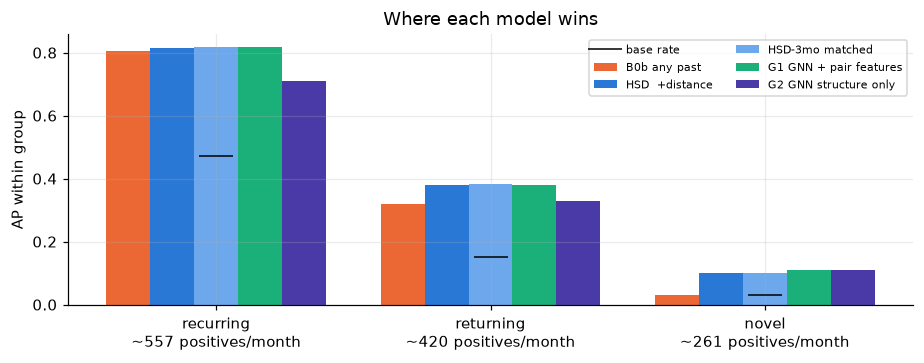

In [11]:
COMPARE = ["B0b any past", MAIN, MATCH, "G1 GNN + pair features", "G2 GNN structure only"]
sub = []
for t in folds:
    yte, g = keep[t][0], groups(t)
    for name in ["recurring", "returning", "novel"]:
        m = g == name
        if yte[m].sum() == 0: continue
        for mod in COMPARE:
            sub.append({"month": str(months[t]), "group": name, "model": mod,
                        "support": int(yte[m].sum()), "candidates": int(m.sum()),
                        "base_rate": yte[m].mean(), "AP": ap(yte[m], keep[t][1][mod][m])})
sub = pd.DataFrame(sub)
tbl = sub.pivot_table(index="group", columns="model", values="AP").reindex(["recurring","returning","novel"])
tbl["base rate"] = sub.groupby("group").base_rate.mean()
tbl["positives/mo"] = sub.groupby("group").support.mean().round(0)
print(tbl.round(3).to_string())

g_order = ["recurring", "returning", "novel"]
fig, ax = plt.subplots(figsize=(8.5, 3.4))
w_ = .16
for i, (mod, col) in enumerate(zip(COMPARE, [ORANGE, BLUE, "#6da7ec", GREEN, "#4a3aa7"])):
    ax.bar(np.arange(3) + i * w_, [sub[(sub.group == g) & (sub.model == mod)].AP.mean() for g in g_order],
           width=w_, color=col, label=mod)
ax.plot(np.arange(3) + 2 * w_, [sub[sub.group == g].base_rate.mean() for g in g_order],
        "k_", markersize=22, label="base rate")
ax.set(xticks=np.arange(3) + 2 * w_, ylabel="AP within group", title="Where each model wins")
ax.set_xticklabels([f"{g}\n~{int(sub[sub.group==g].support.mean())} positives/month" for g in g_order])
ax.legend(fontsize=7.5, ncol=2)
plt.show()

## 11. What the logistic model learned

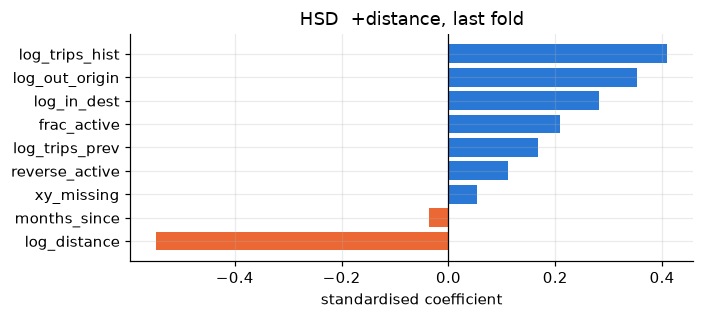

In [12]:
coef = pd.Series(last_w[:-1], index=last_names).sort_values()
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.barh(coef.index, coef.values, color=[ORANGE if v < 0 else BLUE for v in coef.values])
ax.axvline(0, color="k", lw=.8)
ax.set(xlabel="standardised coefficient", title=f"{MAIN}, last fold")
plt.show()

## 12. Save

In [13]:
res.to_csv(f"{OUT}/linkpred_results.csv", index=False)
sub.to_csv(f"{OUT}/linkpred_by_group.csv", index=False)
uni.to_csv(f"{OUT}/linkpred_universe.csv", index=False)
np.savez_compressed(f"{OUT}/linkpred_scores.npz",
                    **{f"y_{months[t]}": keep[t][0] for t in folds},
                    **{f"{mod.split()[0]}_{months[t]}": keep[t][1][mod] for t in folds for mod in COMPARE})
manifest = pd.DataFrame([{"fold": i, "train": f"{months[WARMUP]}..{months[t-1]}", "test": str(months[t]),
                          "candidates": int(OFFDIAG.sum()), "positives": int(labels(t).sum())}
                         for i, t in enumerate(folds)])
manifest.to_csv(f"{OUT}/fold_manifest.csv", index=False)
print(manifest.to_string(index=False))
print("\nsaved 4 files to", OUT)

 fold            train    test  candidates  positives
    0 2021-05..2021-06 2021-07       12882       1079
    1 2021-05..2021-07 2021-08       12882       1239
    2 2021-05..2021-08 2021-09       12882       1541
    3 2021-05..2021-09 2021-10       12882       1537
    4 2021-05..2021-10 2021-11       12882        606
    5 2021-05..2021-11 2021-12       12882       1130
    6 2021-05..2021-12 2022-01       12882       1094
    7 2021-05..2022-01 2022-02       12882       1210
    8 2021-05..2022-02 2022-03       12882       1367
    9 2021-05..2022-03 2022-04       12882       1315
   10 2021-05..2022-04 2022-05       12882       1371
   11 2021-05..2022-05 2022-06       12882       1215
   12 2021-05..2022-06 2022-07       12882       1342
   13 2021-05..2022-07 2022-08       12882       1306

saved 4 files to outputs/results
